In [1]:
%load_ext autoreload 
%autoreload 2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 25)


### Ladda och kontrollera datakvalité  

In [2]:
df = pd.read_csv('../data/health_study_dataset.csv', index_col='id')
df = df.astype({'sex': 'category','smoker': 'category'})
# adds bmi column to the dataframe
df['bmi'] = df['weight'] / (df['height'] / 100) ** 2
print(df.head(3))
print('\nInfo:\n')
df.info()
print('\nMissing Values:\n', df.isna().sum())
print('\nduplicates:', df.duplicated().sum())

    age sex  height  weight  systolic_bp  cholesterol smoker  disease        bmi
id                                                                              
1    57   F   168.9    65.8        141.8         4.58     No        0  23.065698
2    47   M   180.4    95.9        144.8         5.18    Yes        0  29.467653
3    59   F   169.9    82.2        151.7         6.16     No        0  28.476398

Info:

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 1 to 800
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   age          800 non-null    int64   
 1   sex          800 non-null    category
 2   height       800 non-null    float64 
 3   weight       800 non-null    float64 
 4   systolic_bp  800 non-null    float64 
 5   cholesterol  800 non-null    float64 
 6   smoker       800 non-null    category
 7   disease      800 non-null    int64   
 8   bmi          800 non-null    float64 
dtypes: category(2), 

- inga null-värden hittades
- inga dubletter hittades  
- har satt index till id, och lagt till bmi som kolumn för bättre värde av kroppsbyggnad än längd och vikt för sig.  
- Ändrat sex and smoker till `category` datatyp

#### Orimliga värden
undersök eventuella orimliga värden med bmi under 12 och över 50 om det förekommer.  
- det förekommer ej bmi-värden utanför intervallet, det finns därmed inga uppenbara extremvärden.
- min/max värden på längd och ålder är rimliga i tabellen

In [3]:
print(f'Antal individer med BMI < 12 eller > 50: {((df["bmi"] < 12) | (df["bmi"] > 50)).sum()}')
print('\nDescription:\n', df.describe())


Antal individer med BMI < 12 eller > 50: 0

Description:
               age      height      weight  systolic_bp  cholesterol     disease         bmi
count  800.000000  800.000000  800.000000   800.000000   800.000000  800.000000  800.000000
mean    49.426250  171.849250   73.413000   149.178625     4.929150    0.058750   24.933722
std     14.501118    9.804259   13.685059    12.793360     0.848413    0.235303    4.661261
min     18.000000  144.400000   33.700000   106.800000     2.500000    0.000000   12.634903
25%     39.000000  164.775000   64.800000   140.900000     4.327500    0.000000   21.918637
50%     50.000000  171.350000   73.200000   149.400000     4.970000    0.000000   24.703622
75%     59.000000  178.925000   82.600000   157.600000     5.482500    0.000000   28.011842
max     90.000000  200.400000  114.400000   185.900000     7.880000    1.000000   40.141267


#### Spridning

In [4]:
summary = pd.DataFrame({
    'Mean': [df['age'].mean(), df['weight'].mean(), df['height'].mean(), df['systolic_bp'].mean(), df['cholesterol'].mean()],
    'Median': [df['age'].median(), df['weight'].median(), df['height'].median(), df['systolic_bp'].median(), df['cholesterol'].median()],
    'Min': [df['age'].min(), df['weight'].min(), df['height'].min(), df['systolic_bp'].min(), df['cholesterol'].min()],
    'Max': [df['age'].max(), df['weight'].max(), df['height'].max(), df['systolic_bp'].max(), df['cholesterol'].max()]
}, index=['Age', 'Weight', 'Height', 'Systolic BP', 'Cholesterol'])

print(summary.round(2))


               Mean  Median    Min     Max
Age           49.43   50.00   18.0   90.00
Weight        73.41   73.20   33.7  114.40
Height       171.85  171.35  144.4  200.40
Systolic BP  149.18  149.40  106.8  185.90
Cholesterol    4.93    4.97    2.5    7.88


Medelvärden och median ligger väldigt nära varandra för de undersökta variablerna, vilket indikerar relativt symmetriska fördelningar.  
Spridningen ser ut att vara ganska stor i alla variabler.


# Korrelationer



In [5]:
corr = df.select_dtypes(include='number').corr()
print(corr)

                  age    height    weight  systolic_bp  cholesterol   disease       bmi
age          1.000000 -0.004653 -0.017309     0.607578     0.491173  0.021629 -0.011153
height      -0.004653  1.000000  0.320260     0.086297    -0.043344  0.033194 -0.295205
weight      -0.017309  0.320260  1.000000     0.179467     0.256214  0.037424  0.803614
systolic_bp  0.607578  0.086297  0.179467     1.000000     0.368441  0.031059  0.128814
cholesterol  0.491173 -0.043344  0.256214     0.368441     1.000000  0.013729  0.292370
disease      0.021629  0.033194  0.037424     0.031059     0.013729  1.000000  0.018864
bmi         -0.011153 -0.295205  0.803614     0.128814     0.292370  0.018864  1.000000


Finns korrelationer mellan ålder och blodtryck/kolesterol (ett förväntat resultat), men ingenting som verkar påverka sjukdomsrisk med ett tydligt linjärt samband.

Visar även på måttlig korrelation mellan kolesterol och blodtryck, förväntat resultat men kan undersökas vidare om det skiljer mellan olika grupper.

# Demografisk beskrivning

In [6]:
# customized order for my okabe ito palette
okabe_ito= ['#56B4E9','#E69F00','#009E73','#D55E00','#0072B2','#CC79A7','#F0E442','#000000']
sns.set_theme(style='whitegrid', context='notebook')

disease_share = (df['disease'].map({0: 'Ingen sjukdom', 1: 'Sjukdom'})
    .value_counts(normalize=True) * 100)
print('Andel sjukdom vs ingen sjukdom (%):\n',disease_share.round(1))

age_by_sex = df.groupby('sex').agg(
    mean_age=('age', 'mean'),
    median_age=('age', 'median'),
    std_age=('age', 'std'),
    count=('age', 'count'))

print('\nÅldersfördelning mellan könen:\n',age_by_sex)


Andel sjukdom vs ingen sjukdom (%):
 disease
Ingen sjukdom    94.1
Sjukdom           5.9
Name: proportion, dtype: float64

Åldersfördelning mellan könen:
       mean_age  median_age    std_age  count
sex                                         
F    49.868486        50.0  14.485542    403
M    48.977330        49.0  14.521388    397


#### Histogram/KDE över ålder
- Visar populationens sammansättning och skillnader mellan män och kvinnors åldersfördelning i populationen.

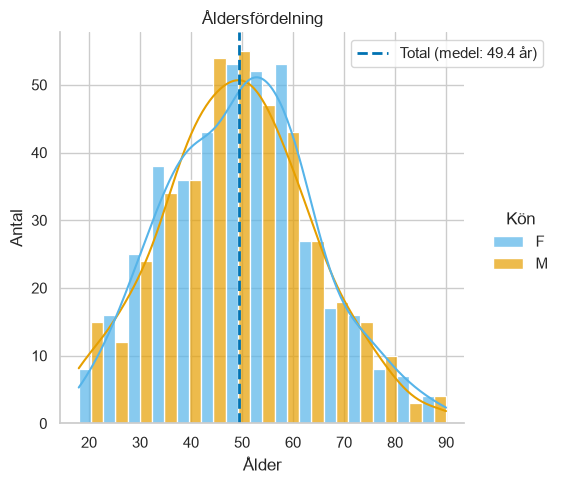

In [23]:
dis_plot_age = sns.displot(data=df, x='age', hue='sex', kde=True, bins=15, palette=okabe_ito[:2], alpha=0.7, multiple='dodge')

mean_age = df['age'].mean()
dis_plot_age.ax.axvline(mean_age, color=okabe_ito[4], linestyle='--', linewidth=2, label=f'Total (medel: {mean_age:.1f} år)')

dis_plot_age.legend.set_title('Kön')
plt.title('Åldersfördelning')
plt.xlabel('Ålder')
plt.ylabel('Antal')
plt.legend(loc='upper left', bbox_to_anchor=(0.7, 1.0))
plt.tight_layout()
plt.show()

Åldersfördelningen är relativt lika mellan män och kvinnor och uppvisar en ungefärlig normalfördelning.  
Diagrammet ger inga tydliga indikationer på större skillnader mellan könen.

#### Histogram/KDE över blodtryck	
- Fördelningen av blodtryck	Identifierar spridning och extremvärden

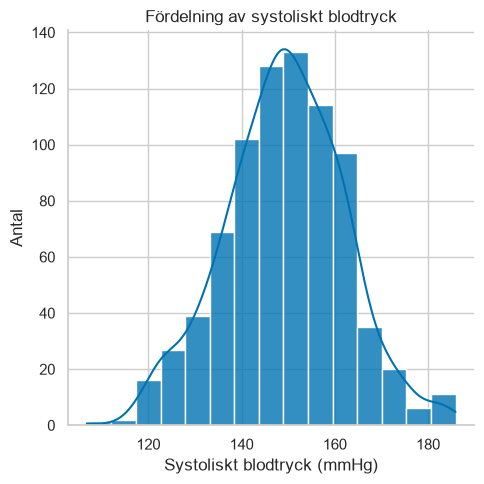

In [21]:
dis_plot_sys = sns.displot(data=df, x='systolic_bp', kde=True, bins=15, color=okabe_ito[4], alpha=0.8)

plt.title('Fördelning av systoliskt blodtryck')
plt.xlabel('Systoliskt blodtryck (mmHg)')
plt.ylabel('Antal')
plt.tight_layout()
plt.show()

Fördelningen är relativt symmetrisk men uppvisar en viss högervridning.  
Den kan betraktas som ungefär normalfördelad, men är inte helt symmetrisk.

#### Stapeldiagram för antal rökare fördelat på kön

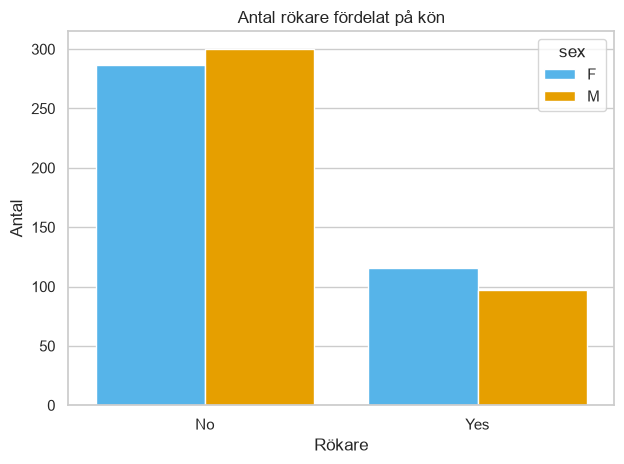

Andel rökare i (%) fördelat på kön:
 smoker    No   Yes
sex               
F       71.2  28.8
M       75.6  24.4


In [19]:
sns.countplot(x='smoker',data=df, palette=okabe_ito[:2], hue='sex', saturation=1)
plt.title('Antal rökare fördelat på kön')
plt.xlabel('Rökare')
plt.ylabel('Antal')
plt.tight_layout()
plt.show()

smoker_share = pd.crosstab(
    df['sex'],
    df['smoker'],
    normalize='index') * 100
print('Andel rökare i (%) fördelat på kön:\n', smoker_share.round(1))

Liten överrepresentation av kvinnor som röker.

# Hälsomässig beskrivning

#### Kolesterol – blodtryck	
- Finns det ett samband mellan högt kolesterol och högt blodtryck?  
Värt att undersöka vidare då korrelationstabellen visade på en svag till måttlig korrelation.  
Diagrammet här visar även på en viss skillnad mellan män och kvinnor.

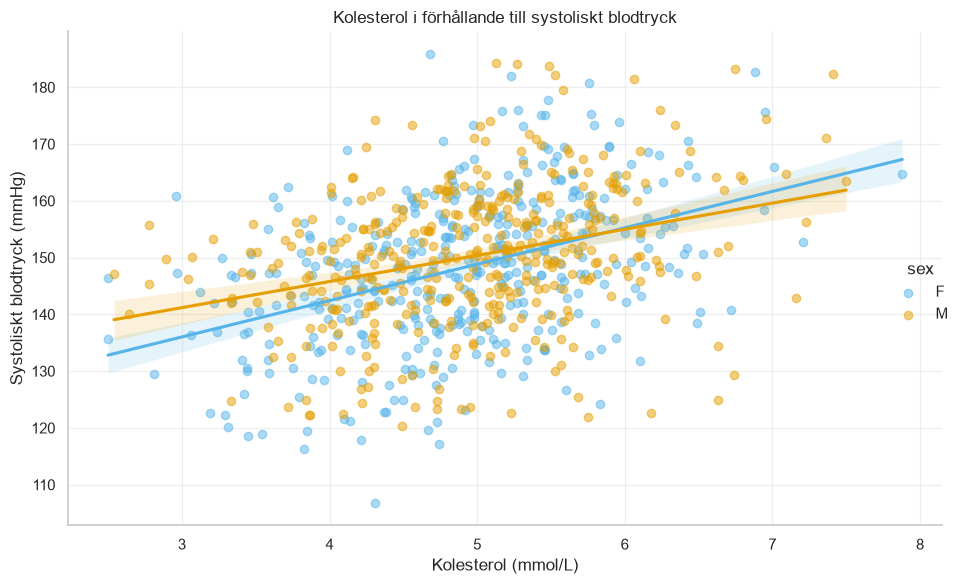

Korrelation mellan kolesterol och systoliskt blodtryck uppdelat efter kön:
sex             
F    systolic_bp    0.411753
M    systolic_bp    0.317401
Name: cholesterol, dtype: float64


In [18]:
sns.lmplot(data=df, x='cholesterol', y='systolic_bp', hue='sex', palette=okabe_ito[:2], scatter_kws={'alpha': 0.5}, height=6, aspect=1.5)

plt.title('Kolesterol i förhållande till systoliskt blodtryck')
plt.xlabel('Kolesterol (mmol/L)')
plt.ylabel('Systoliskt blodtryck (mmHg)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Korrelation mellan kolesterol och systoliskt blodtryck uppdelat efter kön:\n{df.groupby('sex')[['cholesterol', 'systolic_bp']].corr().iloc[[1, 3],0]}')

Visar en svag till måttlig korrelation mellan kolesterol och systoliskt blodtryck, totalt: 0.368441 men verkar vara lite högre för kvinnor i detta dataset, 0.411753 mot 0.317401 för män.  
Det kan vara intressant att undersöka om skillnaden kvarstår efter kontroll av exempelvis ålder.

# Undersökning av sjukdomsrisk
#### A. Blodtryck uppdelat efter sjukdom

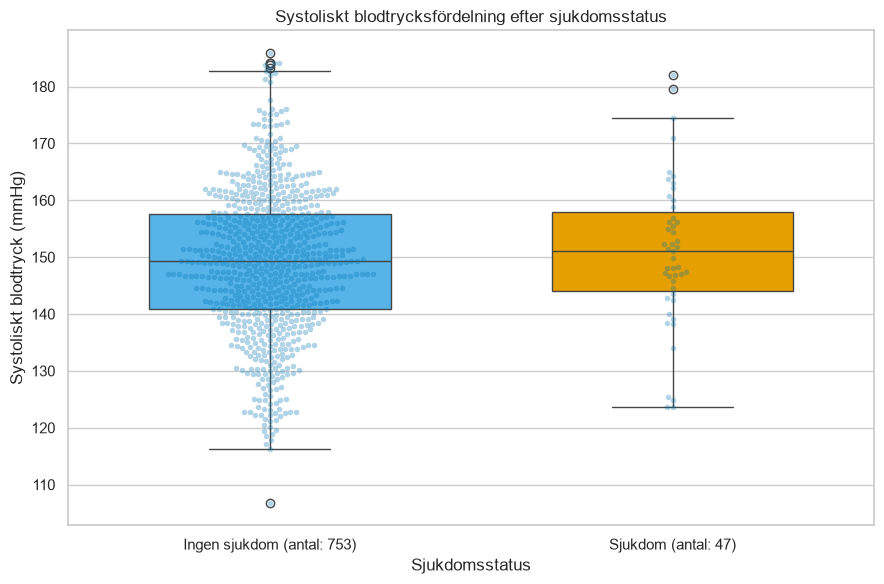

In [16]:
disease_counts = df['disease'].value_counts()
labels = {0: f'Ingen sjukdom (antal: {disease_counts.get(0, 0)})',
        1: f'Sjukdom (antal: {disease_counts.get(1, 0)})'}

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='systolic_bp',hue='disease',palette=okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='systolic_bp',color=okabe_ito[4],alpha=0.3,size=4,ax=ax)
plt.title('Systoliskt blodtrycksfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Systoliskt blodtryck (mmHg)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av systoliskt blodtryck uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.  
 Medianvärden och spridning verkar vara relativt lika.   
 I detta dataset finns därför inget tydligt visuellt stöd för ett samband mellan systoliskt blodtryck och sjukdomsstatus.

#### B. Kolesterol uppdelat efter sjukdom

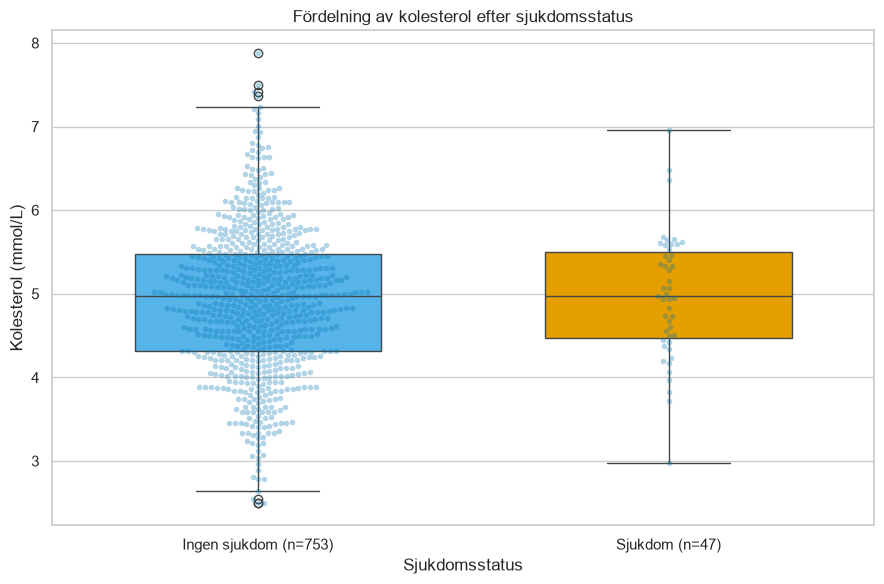

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='cholesterol',hue='disease',palette=okabe_ito[:2],legend=False, ax=ax, width=0.6, saturation=1)
sns.swarmplot(data=df,x='disease',y='cholesterol',color=okabe_ito[4],alpha=0.3,size=4,ax=ax)
plt.title('Fördelning av kolesterol efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Kolesterol (mmol/L)')
plt.xticks([0, 1], [labels[0], labels[1]])
plt.tight_layout()
plt.show()

Fördelningen av kolesterol uppvisar inga tydliga skillnader mellan grupperna med respektive utan sjukdom.  
 Medianvärden och spridning verkar vara relativt lika.   
 I detta dataset finns därför inget tydligt visuellt stöd för ett samband mellan kolesterol och sjukdomsstatus.

#### C. Sjukdomsförekomst bland rökare och icke-rökare

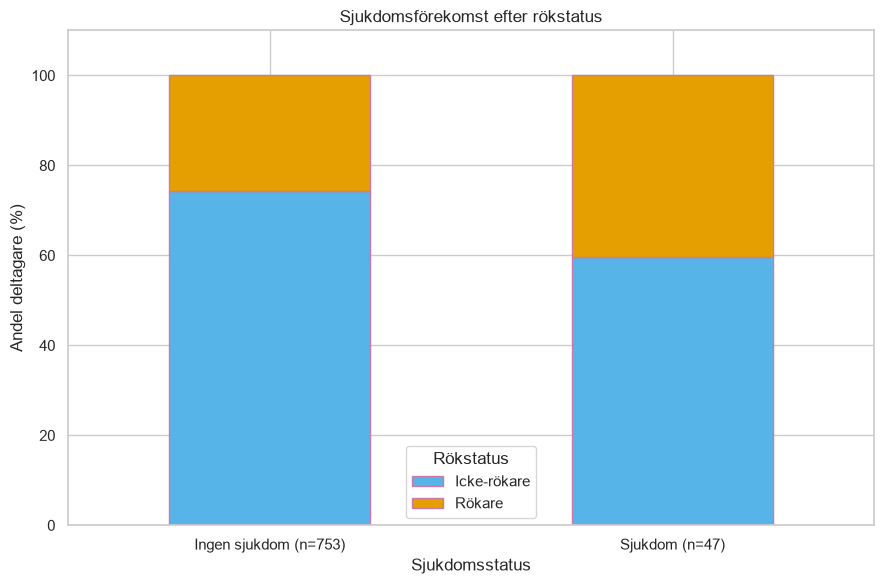

Fördelning av rökare med och utan sjukdom:
         Ingen sjukdom   Sjukdom
smoker                         
No          95.229983  4.770017
Yes         91.079812  8.920188


In [ ]:
smoker_proportion = pd.crosstab(df['disease'],df['smoker'], normalize='index').reindex(columns=['No', 'Yes']) * 100
disease_counts = df['disease'].value_counts()

labels = [f'Ingen sjukdom (n={disease_counts.get(0, 0)})',f'Sjukdom (n={disease_counts.get(1, 0)})']
smoker_proportion.index = labels

ax = smoker_proportion.plot(kind='bar', stacked=True, color=[okabe_ito[0], okabe_ito[1]], edgecolor=okabe_ito[5], figsize=(9, 6), alpha = 1)

ax.set_title('Sjukdomsförekomst efter rökstatus')
ax.set_xlabel('Sjukdomsstatus')
ax.set_ylabel('Andel deltagare (%)')
ax.set_ylim(0, 110)
ax.legend(['Icke-rökare', 'Rökare'],title='Rökstatus')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

smoker_risk = pd.crosstab(
    df['smoker'],
    df['disease'],
    normalize='index'
) * 100
smoker_risk.columns = ['Ingen sjukdom', 'Sjukdom']
print('Fördelning av rökare med och utan sjukdom:\n', smoker_risk)

Andelen rökare är högre bland individer med sjukdom än bland individer utan sjukdom.  
Detta indikerar ett möjligt samband mellan rökning som riskfaktor och sjukdomsstatus.

#### D. Ålder uppdelat efter sjukdomsstatus

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x='disease',y='age',hue='disease',palette=okabe_ito[:2],legend=False, ax=ax, width=0.6)

sns.swarmplot(data=df,x='disease',y='age',color=okabe_ito[4],alpha=0.3,size=4,ax=ax)
plt.xticks([0, 1], [labels[0], labels[1]])

plt.title('Åldersfördelning efter sjukdomsstatus')
plt.xlabel('Sjukdomsstatus')
plt.ylabel('Ålder (år)')

Medianåldern är relativt likartad mellan grupperna. Diagrammet visar inga tydliga skillnader i åldersfördelning mellan individer med och utan sjukdom.  
Resultatet bör dock tolkas med viss försiktighet eftersom sjukdomsgruppen är betydligt mindre.